# 6. Which structure changes affect recovery?

Notebook 4 shows faster recovery at later reversals with continued search. Which structure operation gives it?

Use the target, reversals, seeds, and examples of notebook 4.
Train the separate-candidate method up to the first reversal. Copy the trained network for every condition.
Permit no structure changes, only connection changes, only whole-unit replacement, or both operations.
Connection changes include candidate replacement, promotion, and active connection removal.
Whole-unit replacement also replaces the selected unit's connections, as required by that operation.
A further control permits candidate replacement and promotion but protects every active connection.
Every condition continues to update weights and step sizes.
The curves show mean RMSE over five seeds without uncertainty bands. The printed measures are those of notebook 4.

## Observed results

Without connection changes, with or without unit replacement, about 80% of the reversed-output weight stays on LTUs with their shadow there.
These conditions lose features at every reversal, and their error rises a second time after each one.
Unit replacement alone gives the highest error after the first reversal.

All three conditions with connection changes reduce that share to 0.07 or less by the fourth reversal.
They recover fast from the later reversals. This includes the control with every active connection protected.
Thus, removal of active connections is not necessary for the faster later recovery. Candidate replacement and promotion are sufficient here.

## Explanations that the data do not establish

- Promotions connect the reversed output to LTUs whose shadow is on the fixed output, as in notebook 4. No run tests this alone.
- Why unit replacement alone is worse than no structure changes.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


In [2]:
conditions = {'fixed': ('candidates', {'frozen': True}),
              'connections_only': ('candidates', {'units': False}),
              'units_only': ('candidates', {'connections': False}),
              'both': ('candidates', {}),
              'candidates_only': ('candidates', {'units': False, 'remove_active': False})}
curves, records = m.run_reversals(conditions)


fixed: RMSE after the first reversal 0.512


connections_only: RMSE after the first reversal 0.349


units_only: RMSE after the first reversal 0.624


both: RMSE after the first reversal 0.335


candidates_only: RMSE after the first reversal 0.348


73.4s for 5 seeds per condition


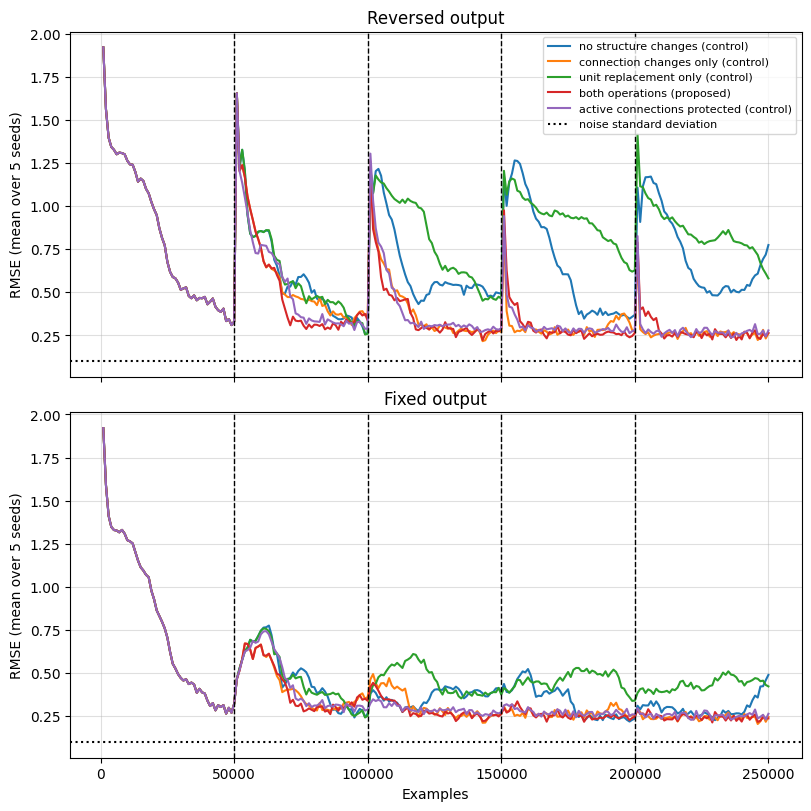

In [3]:
labels = {'fixed': 'no structure changes (control)',
          'connections_only': 'connection changes only (control)',
          'units_only': 'unit replacement only (control)',
          'both': 'both operations (proposed)',
          'candidates_only': 'active connections protected (control)'}
m.plot(curves, labels, reversals=True)


In [4]:
m.shadow_summary(records, labels)


no structure changes (control)
  share of reversed-output weight on LTUs with their shadow there: 0.81  0.80  0.81  0.81
  lost features, shadow on reversed output: 18/19  13/18  9/13  11/16;  on fixed output: 0/18  0/17  0/18  0/18
connection changes only (control)
  share of reversed-output weight on LTUs with their shadow there: 0.81  0.41  0.17  0.05
  lost features, shadow on reversed output: 18/19  8/9  2/4  0/1;  on fixed output: 0/18  1/21  0/20  0/20
unit replacement only (control)
  share of reversed-output weight on LTUs with their shadow there: 0.81  0.80  0.81  0.82
  lost features, shadow on reversed output: 18/19  15/18  11/14  9/13;  on fixed output: 0/18  0/17  0/18  0/18
both operations (proposed)
  share of reversed-output weight on LTUs with their shadow there: 0.81  0.41  0.20  0.05
  lost features, shadow on reversed output: 18/19  9/9  3/4  1/1;  on fixed output: 1/18  0/20  0/21  0/21
active connections protected (control)
  share of reversed-output weight on LT